In [1]:
import sys
sys.path.insert(0, r'../../../quetzal')

### from quetzal.engine import simplify
from quetzal.model import stepmodel, preparationmodel
from quetzal.io import excel
from quetzal.io import road as road_io
from quetzal.io import importer
from syspy.spatial.spatial import nearest_geometry

import os
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import math
import numba as nb
import h3

from osm_importer.importer import import_road_network, simplify_road_network, simplify_bicycle_network
from osm_importer.overpass import get_bbox, get_overpass_query

import zipfile
import json

io_engine= 'pyogrio'

In [2]:
var = excel.read_var(r'../../inputs/parameters.xlsx', scenario='base')

In [3]:
BIKE_SPEED = var['bike_speed'].to_dict()

# Importer road network directement depuis la zone

In [4]:
zones = gpd.read_file('../../inputs/zones/zones_gironde.gpkg').to_crs(epsg=4326)
poly = shapely.union_all(zones.geometry.values.tolist())

In [5]:
HIGHWAY_COLUMNS = ['highway', 'maxspeed', 'lanes', 'name', 'oneway', 'surface']

CYCLEWAY_COLUMNS = ['cycleway', 'bicycle', 'foot',
        'oneway:bicycle', 'busway', 'cycleway:both',
        'cycleway:both:lane', 'cycleway:left', 'cycleway:left:lane',
        'cycleway:left:oneway', 'cycleway:right', 'cycleway:right:lane',
        'cycleway:right:oneway', 'cycleway:contraflow', 'cycleway:contraflow']

In [6]:
split_direction = True
extended_cycleway = True
add_elevation = True

In [7]:
bbox = (poly.bounds[1], poly.bounds[0], poly.bounds[3], poly.bounds[2])
highway_list = ['primary', 'secondary', 'tertiary', 'motorway', 'trunk',
                'primary_link', 'secondary_link', 'tertiary_link', 'motorway_link', 'trunk_link',
                'living_street', 'residential', 'unclassified', 'service', 'cycleway', 'path']
cycleway_list = []
columns = HIGHWAY_COLUMNS + CYCLEWAY_COLUMNS

In [8]:
links, nodes = import_road_network(bbox, highway_list, cycleway_list, columns)
links.index = [f'rlink_{i}' for i in links.index]
links['a'] = links['a'].apply(lambda x: f'rnode_{x}')
links['b'] = links['b'].apply(lambda x: f'rnode_{x}')
nodes.index = [f'rnode_{i}' for i in nodes.index]

links = gpd.sjoin(
    links, gpd.GeoDataFrame(geometry=[poly], crs=4326), how='inner', predicate='intersects'
).drop(columns='index_right')

rlinks_raw, rnodes_raw = links.copy(), nodes.copy()

In [9]:
from shapely.ops import transform
 
def _reverse_geom(geom):
    def _reverse(x, y, z=None):
        if z:
            return x[::-1], y[::-1], z[::-1]
        return x[::-1], y[::-1]
    return transform(_reverse, geom)

def bike_lane_category(x):
    bi = 0 # bike_index
    col = False # create opposite_link
    bio = 0 # bike_index_opposite

    if x['highway']=='cycleway' : return 5, False, 5
    elif x['cycleway:both']=='track' : return 5, True, 5
    elif x['cycleway:right']=='track':
        if x['cycleway:right:oneway'] == 'no' : return 5, True, 5
        else : bi=5
    elif x['cycleway:left'] == 'track':
        if x['cycleway:left:oneway'] == 'no' : return 5, True, 5
        else : col, bio=True, 5
    
    elif x['cycleway']=='lane' : return 4, False, 4
    elif x['cycleway:both']=='lane' : return 4, True, 4
    elif x['cycleway:right']=='lane':
        if x['cycleway:right:oneway'] == 'no' : return 4, True, 4
        else : bi=4
    elif x['cycleway:left'] == 'lane':
        if x['cycleway:left:oneway'] == 'no' : return 4, True, 4
        else : col, bio=True, 4

    elif x['cycleway']=='share_busway' : return 3, False, 3
    elif (x['highway'] in ['busway', 'service']) & (x['bicycle'] in ['yes', 'designated']) : return 3, False, 3
    elif x['cycleway:both'] in ['share_busway'] : return 3, True, 3
    elif x['cycleway:right'] in ['share_busway'] : bi=3
    elif x['cycleway:left'] in ['share_busway'] : col, bio = True, 3
    
    elif (x['highway']=='path') & ((x['bicycle'] in ['designated', 'yes', 'permissive']) | (x['foot']=='designated')) | \
            ((x['highway']=='cycleway') & (x['foot']=='yes')) | \
            ((x['highway']=='footway') & (x['bicycle']=='yes')):
        return 2, False, 2

    elif (x['oneway'] == 'yes') & (x['oneway:bicycle']=='no'):
        return 0, True, 1

    return [bi, col, bio]

In [10]:
for col in CYCLEWAY_COLUMNS:
    if col not in rlinks_raw.columns:
        rlinks_raw[col] = None

rlinks_raw['res'] = rlinks_raw.apply(bike_lane_category, 1)
rlinks_raw['bike_index'] = rlinks_raw['res'].apply(lambda x: x[0])
rlinks_raw['create_opposite_link'] = rlinks_raw['res'].apply(lambda x: x[1])
rlinks_raw['bike_index_opposite'] = rlinks_raw['res'].apply(lambda x: x[2])
rlinks_raw.drop(columns='res', inplace=True)

rlinks_raw['create_opposite_link'] = rlinks_raw['create_opposite_link']&(rlinks_raw['oneway']=='yes')

In [11]:
### rlinks_raw.to_file('../../inputs/road/rlinks_raw_small_.geojson')
### rnodes_raw.to_file('../../inputs/road/rnodes_raw_small_.geojson')

In [12]:
rlinks, rnodes = simplify_road_network(rlinks_raw, rnodes_raw, add_elevation, split_direction, keep_detour=True)

rlinks['bike_index'] = rlinks['bike_index'].apply(lambda x: max(x) if isinstance(x, list) else x)
rlinks['bike_index_opposite'] = rlinks['bike_index_opposite'].apply(lambda x: max(x) if isinstance(x, list) else x)
rlinks['create_opposite_link'] = rlinks['create_opposite_link'].apply(lambda x: max(x) if isinstance(x, list) else x)

In [13]:
rlinks['bike_index'].value_counts()

bike_index
0    501511
5     19317
4      8688
2      5006
3      1494
Name: count, dtype: int64

In [14]:
rlinks.drop(columns=CYCLEWAY_COLUMNS+['cycleway_reverse'], errors='ignore', inplace=True)

rlinks['bike'] = ~rlinks['highway'].isin(['motorway', 'motorway_link', 'trunk', 'trunk_link'])
bike_nodes = set(rlinks.loc[rlinks['bike'], 'a'].values.tolist() + rlinks.loc[rlinks['bike'], 'b'].values.tolist())
rnodes['bike'] = rnodes.index.isin(list(bike_nodes))

rlinks['car'] = ~(rlinks['highway'].isin(['cycleway', 'path', 'busway', 'pedestrian', 'footway']) | rlinks['speed'].isna())
car_nodes = set(rlinks.loc[rlinks['car'], 'a'].values.tolist() + rlinks.loc[rlinks['car'], 'b'].values.tolist())
rnodes['car'] = rnodes.index.isin(list(car_nodes))

In [15]:
opposite_links = rlinks.loc[rlinks['create_opposite_link']].copy()
opposite_links['lanes'] = 1
opposite_links['incline'] *= -1
opposite_links['geometry'] = opposite_links['geometry'].apply(_reverse_geom)
opposite_links[['a', 'b']] = opposite_links[['b', 'a']].copy()
opposite_links['car'] = False
opposite_links['bike'] = True
opposite_links['bike_index'] = opposite_links['bike_index_opposite'].copy()
opposite_links.index += '_rb'

rlinks = pd.concat([rlinks, opposite_links]).drop(columns=['bike_index_opposite', 'create_opposite_link'])

In [16]:
hierarchy = {
    "motorway": 0,
    "trunk": 1,
    "primary": 2,
    "primary_link": 2.5,
    "secondary": 3,
    "secondary_link": 3.5,
    "tertiary": 4,
    "tertiary_link": 4.5,
    "residential": 5,
    "service": 5,
    "living_street": 6,
    "path": 6.5,
    "pedestrian": 7
}

rlinks['hierarchy_highway'] = rlinks['highway'].map(hierarchy)
rlinks = rlinks.sort_values(['hierarchy_highway', 'length'], ascending=[True, True])
rlinks.drop_duplicates(subset=['a', 'b'], keep='first', inplace=True)
rlinks.drop(columns='hierarchy_highway', inplace=True)
rlinks.index.name = 'index'

In [17]:
rnodes = rnodes.reset_index(names='index').drop_duplicates(subset='index').set_index('index')

In [18]:
### rlinks.to_file('../../inputs/road/rlinks_corrected_.geojson')
### rnodes.to_file('../../inputs/road/rnodes_corrected_.geojson')

In [19]:
#rlinks = gpd.read_file('../../inputs/road/rlinks_corrected_.geojson')
#rnodes = gpd.read_file('../../inputs/road/rnodes_corrected_.geojson')

# Create model

In [20]:
UTM_EPSG = 3857  # France
sm = stepmodel.StepModel(epsg=UTM_EPSG, coordinates_unit='meter')

In [21]:
input_folder = '../../inputs/'

In [22]:
def read_file(path,engine):
    gdf = gpd.read_file(path, engine=engine)
    if 'index' in gdf.columns:
        gdf = gdf.set_index('index')
    else:
        gdf.index.name = 'index'
    return gdf

def read_links(filename, engine):
    links = read_file(filename, engine=engine)
    with open(filename, 'r') as j:
        json_data = json.loads(j.read())
    json_prop = json_data['features'][0]['properties'].keys()
    missing_columns = set(json_prop).difference(links.columns)
    for col in missing_columns:
        if col != 'index':
            d = {f['properties']['index']: f['properties'].get(col) for f in json_data['features']}
            links[col] = links.index.map(d) 

    return links

In [23]:
links = read_links(input_folder + r'pt/links.geojson', engine=io_engine)
nodes = read_file(input_folder + r'pt/nodes.geojson', engine=io_engine)

In [24]:
sm.links = links.to_crs('EPSG:{}'.format(UTM_EPSG))
sm.nodes = nodes.to_crs('EPSG:{}'.format(UTM_EPSG))
sm.road_links = rlinks.to_crs('EPSG:{}'.format(UTM_EPSG))
sm.road_nodes = rnodes.to_crs('EPSG:{}'.format(UTM_EPSG))

# enforce types and default values

In [25]:
# DEFAULT
sm.links["headway"].fillna(20 * 60, inplace=True)

# LINKS
float_types = ["headway", "length", "speed", "time"]
int_types = ["link_sequence"]

for col in float_types:
    sm.links[col] = sm.links[col].map(float)
for col in int_types:
    sm.links[col] = sm.links[col].map(int)

# RLINKS
float_types = ["length", "speed", "time"]
int_types = ["lanes"]
for col in float_types:
    sm.road_links[col] = sm.road_links[col].map(float)
for col in int_types:
    sm.road_links[col] = sm.road_links[col].fillna(1).map(int)

# Road Network

## Fix

In [26]:
from  shapely.ops import transform
 
def _reverse_geom(geom):
    def _reverse(x, y, z=None):
        if z:
            return x[::-1], y[::-1], z[::-1]
        return x[::-1], y[::-1]
    return transform(_reverse, geom)
 
def split_quenedi_rlinks(rlinks, not_oneway=[True, 1, "1"]):
    if 'oneway' not in rlinks.columns:
        print('no column oneway. do not split')
        return rlinks
    links_r = rlinks[~(rlinks['oneway'].isin(not_oneway))].copy()
    if len(links_r) == 0:
        print('all oneway, nothing to split')
        return rlinks
    # apply _r features to the normal non r features
    r_cols = [col for col in links_r.columns if col.endswith('_r')]
    cols = [col[:-2] for col in r_cols]
    for col, r_col in zip(cols, r_cols):
        links_r[col] = links_r[r_col]
    # reindex with _r
    links_r.index = links_r.index.astype(str) + '_r'
    # reverse links (a=>b, b=>a)
    links_r = links_r.rename(columns={'a': 'b', 'b': 'a'})
    links_r['geometry'] = links_r['geometry'].apply(lambda g: _reverse_geom(g))
    rlinks = pd.concat([rlinks, links_r])
    return rlinks

In [27]:
rlinks_ = split_quenedi_rlinks(sm.road_links)
to_delete = [col for col in rlinks_.columns if col.endswith('_r')]
rlinks_.drop(columns=to_delete,inplace=True)
sm.road_links = rlinks_.copy().to_crs(epsg=3857)

all oneway, nothing to split


In [28]:
sm_bike = sm.copy()
sm_bike.road_links = sm_bike.road_links.loc[sm_bike.road_links['bike']]
sm_bike.road_nodes = sm_bike.road_nodes.loc[sm_bike.road_nodes['bike']]

sm_car = sm.copy()
sm_car.road_links = sm_car.road_links.loc[sm_car.road_links['car']]
sm_car.road_nodes = sm_car.road_nodes.loc[sm_car.road_nodes['car']]

In [29]:
sm_bike.integrity_fix_road_network()
sm_car.integrity_fix_road_network()

direct: 225927it [00:41, 5484.30it/s]
reversed: 225927it [00:34, 6570.37it/s]
225826it [00:38, 5875.96it/s]


Reached max recursive_depth


direct: 212809it [00:30, 7033.41it/s]
reversed: 212809it [00:27, 7743.67it/s] 
212752it [00:32, 6617.84it/s]


In [30]:
main_rnetwork = sm.road_links[sm.road_links.highway.isin(["motorway", "motorway_link", 
                                                          "trunk", "trunk_link", 
                                                          "primary", "primary_link", 
                                                          "secondary", "secondary_link"])]

to_keep_indices = list(main_rnetwork.index)

In [31]:
len(to_keep_indices)

49879

In [32]:
import h3
import geopandas as gpd
import numpy as np
import pandas as pd
from shapely.geometry import Polygon, Point

def polygon_to_h3_zones_gdf(polygon_4326, resolution):
    poly = h3.LatLngPoly([(y, x) for x, y in polygon_4326.exterior.coords[1:]])
    cells = h3.h3shape_to_cells(poly, res=resolution)
    zones = gpd.GeoDataFrame({"geometry" : [Point(h3.cell_to_latlng(c)[::-1]) for c in cells]})
    return zones.set_crs(epsg=4326)

In [33]:
resolution = 6
force = False
keep_reversed=True

rl_cols = sm.road_links.columns
## BUILD H3 ZONING
# get latlong perimeter
print("build H3 zoning")
perimeter_df = gpd.GeoDataFrame({"geometry": [sm.road_links.to_crs(epsg=4326).unary_union.convex_hull]})
perimeter = perimeter_df.geometry.values[0]
# build zoning
zones = polygon_to_h3_zones_gdf(perimeter, resolution)

build H3 zoning


In [34]:
zones.index = 'zone_' + zones.index.astype(str)

In [35]:
# check n zones
if not force:
    assert(len(zones)<1500), f"Warning: the algorithm will use {len(zones)} zones which is high and might kill your computer! Rerun with force=True if you are sure to proceed"

In [36]:
# prepare model and build dumb volumes
print("prepare model")
sm.zones = zones.set_crs(epsg=4326).to_crs(epsg=sm.epsg)
volumes = pd.DataFrame(
    index=pd.MultiIndex.from_product([zones.index, zones.index]),
    data=np.ones(len(zones.index)**2),
    columns=["volume"]
)

sm.volumes = volumes.reset_index().rename(columns={"level_0": "origin", "level_1": "destination"})

prepare model


In [37]:
sm_bike.zones, sm_bike.volumes = sm.zones.copy(), sm.volumes.copy()
sm_car.zones, sm_car.volumes = sm.zones.copy(), sm.volumes.copy()

In [38]:
sm_bike.preparation_ntlegs(zone_to_road=True, road_to_transit=False)
sm_car.preparation_ntlegs(zone_to_road=True, road_to_transit=False)

In [39]:
### Keep only zones close enough to the road network (for which an ntleg has been created)
# for bike network
sm_bike.zones = sm_bike.zones.reset_index(names='index')
sm_bike.zones = sm_bike.zones.loc[sm_bike.zones['index'].isin(sm_bike.zone_to_road['a'].values.tolist()) | sm_bike.zones['index'].isin(sm_bike.zone_to_road['b'].values.tolist())]

sm_bike.volumes = sm_bike.volumes.loc[sm_bike.volumes['origin'].isin(sm_bike.zones['index'].values.tolist()) & sm_bike.volumes['destination'].isin(sm_bike.zones['index'].values.tolist())]
sm_bike.zones.set_index('index', inplace=True)

### TODO : adapt speed in bike network (wait for Royston input)
sm_bike.road_links['speed'] = sm_bike.road_links.apply(lambda x: max(x['speed']*BIKE_SPEED['bike_speed_factor_no_infra'], BIKE_SPEED['max_bike_speed_no_infra']) if (x['bike_index'] < 2) else BIKE_SPEED['bike_speed_infra'], 1)
sm_bike.road_links['time'] = sm_bike.road_links['length']/sm_bike.road_links['speed']*3.6

# for car network
sm_car.zones = sm_car.zones.reset_index(names='index')
sm_car.zones = sm_car.zones.loc[sm_car.zones['index'].isin(sm_car.zone_to_road['a'].values.tolist()) | sm_car.zones['index'].isin(sm_car.zone_to_road['b'].values.tolist())]

sm_car.volumes = sm_car.volumes.loc[sm_car.volumes['origin'].isin(sm_car.zones['index'].values.tolist()) & sm_car.volumes['destination'].isin(sm_car.zones['index'].values.tolist())]
sm_car.zones.set_index('index', inplace=True)

In [40]:
# run pathfinder and assignment
print("run pathfinder for bike network")
sm_bike.step_road_pathfinder(method='aon')

run pathfinder for bike network


In [41]:
print("run pathfinder for car network")
sm_car.step_road_pathfinder(method='aon')

run pathfinder for car network


In [42]:
sm_bike.analysis_car_los()
sm_car.analysis_car_los()

In [43]:
sm_bike.los = sm_bike.car_los.copy()
sm_bike.los[("volume", "probability")] = 1
sm_bike.segments=["volume"]
print("run assigmnent")
sm_bike.step_assignment(road=True)

sm_car.los = sm_car.car_los.copy()
sm_car.los[("volume", "probability")] = 1
sm_car.segments=["volume"]
print("run assigmnent")
sm_car.step_assignment(road=True)

run assigmnent
run assigmnent


In [44]:
sm.road_links['volume_bike'] = sm.road_links.index.map(sm_bike.road_links[('volume', 'car')].to_dict())
sm.road_links['volume_car'] = sm.road_links.index.map(sm_car.road_links[('volume', 'car')].to_dict())
sm.road_links['volume'] = sm.road_links['volume_car'].fillna(0) + sm.road_links['volume_bike'].fillna(0)

In [45]:
# Filter road_links
print("filter")
keep_loc = sm.road_links.index.isin(to_keep_indices)
volume_loc = sm.road_links['volume']>0
keep_loc = (keep_loc) | (volume_loc)
if keep_reversed:
    ## force add reversed links for link to keep
    reversed_loc = sm.road_links.loc[(keep_loc)|(sm.road_links['volume']>0)].index
    reversed_to_add_loc = []
    for x in reversed_loc:
        reversed_to_add_loc += [x.split("_r")[0], x.split("_r")[0] + "_r"]
    keep_loc = (keep_loc) | (sm.road_links.index.isin(reversed_to_add_loc))

rl = sm.road_links.loc[keep_loc]

# run integrity checks
print("integrity checks")
clean = sm.copy()
clean.road_links = rl
node_indices = list(set(rl["a"]).union(set(rl["b"])))
clean.road_nodes = sm.road_nodes.loc[node_indices]
clean.integrity_fix_road_network(recursive_depth=10)

filter
integrity checks


direct: 58343it [00:02, 19604.33it/s]
reversed: 58343it [00:02, 21276.14it/s]
58218it [00:03, 18639.62it/s]


In [46]:
### ### Faire ça zone par zone permettrait d'avoir un résultat plus fin sur la métropole où on pourrait imposer une résolution plus
### ### faible
### 
### resolution = 6
### force = False
### keep_reversed=True
### 
### rl_cols = sm.road_links.columns
### ## BUILD H3 ZONING
### # get latlong perimeter
### print("build H3 zoning")
### perimeter_df = gpd.GeoDataFrame({"geometry": [sm.road_links.to_crs(epsg=4326).unary_union.convex_hull]})
### perimeter = perimeter_df.geometry.values[0]
### # build zoning
### zones = polygon_to_h3_zones_gdf(perimeter, resolution)
### zones.index = 'zone_' + zones.index.astype(str)
### # check n zones
### if not force:
###     assert(len(zones)<1500), f"Warning: the algorithm will use {len(zones)} zones which is high and might kill your computer! Rerun with force=True if you are sure to proceed"
### # prepare model and build dumb volumes
### print("prepare model")
### sm.zones = zones.set_crs(epsg=4326).to_crs(epsg=sm.epsg)
### volumes = pd.DataFrame(
###     index=pd.MultiIndex.from_product([zones.index, zones.index]),
###     data=np.ones(len(zones.index)**2),
###     columns=["volume"]
### )
### sm.volumes = volumes.reset_index().rename(columns={"level_0": "origin", "level_1": "destination"})
### sm.preparation_ntlegs(zone_to_road=True, road_to_transit=False)
### sm.zones = sm.zones.reset_index(names='index')
### sm.zones = sm.zones.loc[sm.zones['index'].isin(sm.zone_to_road['a'].values.tolist()) | sm.zones['index'].isin(sm.zone_to_road['b'].values.tolist())]
### 
### sm.volumes = sm.volumes.loc[sm.volumes['origin'].isin(sm.zones['index'].values.tolist()) & sm.volumes['destination'].isin(sm.zones['index'].values.tolist())]
### sm.zones.set_index('index', inplace=True)
### # run pathfinder and assignment
### print("run pathfinder")
### sm.step_road_pathfinder(method='aon')
### sm.analysis_car_los()
### sm.los = sm.car_los.copy()
### sm.los[("volume", "probability")] = 1
### # sm.segments=["volume"]
### # print("run assigmnent")
### # sm.step_assignment(road=True)

In [47]:
rnodes, rlinks = clean.road_nodes.copy(), clean.road_links[rl_cols].copy()

# adapt to zoning

<Axes: >

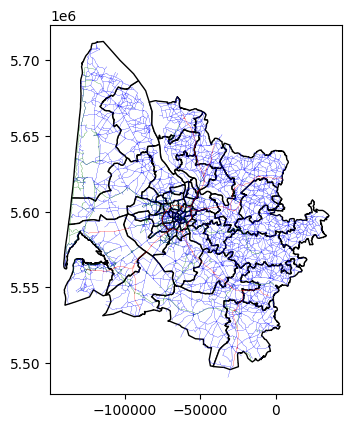

In [48]:
zones = gpd.read_file(input_folder + "zones/zones_gironde.gpkg").to_crs(epsg=3857)
base = zones.plot(color='white', edgecolor='black')
rlinks.loc[rlinks['bike'] & rlinks['car']].plot(color='blue', ax=base, linewidth=0.1)
rlinks.loc[rlinks['bike'] & (~rlinks['car'])].plot(color='green', ax=base, linewidth=0.1)
rlinks.loc[rlinks['car'] & (~rlinks['bike'])].plot(color='red', ax=base, linewidth=0.1)

In [49]:
len(rnodes), len(rlinks)

(58218, 113173)

In [50]:
sm.road_nodes = rnodes.copy()
sm.road_links = rlinks.copy()
sm.integrity_fix_road_network(recursive_depth=10)

direct: 58218it [00:03, 18247.52it/s]
reversed: 58218it [00:02, 19612.56it/s]
58218it [00:03, 18919.94it/s]


In [51]:
sm.road_links.to_crs(epsg=4326).to_file(input_folder + f"road/simple_rl.geojson")
sm.road_nodes.to_crs(epsg=4326).to_file(input_folder + f"road/simple_rn.geojson")